In [1]:
import warnings
import math
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from scipy.stats import skew, boxcox # skew -> carpiklik durumunu numeric olarak olcen bir kutuphane.

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

warnings.filterwarnings("ignore")

In [9]:
# ZN: proportion of residential land zoned for lots over 25,000 sq.ft.
# INDUS: proportion of non-retail business acres per town
# CHAS: Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
# NOX: nitric oxides concentration (parts per 10 million)
# RM: average number of rooms per dwelling
# AGE: proportion of owner-occupied units built prior to 1940
# DIS: weighted distances to ﬁve Boston employment centers
# RAD: index of accessibility to radial highways
# TAX: full-value property-tax rate per $10,000
# PTRATIO: pupil-teacher ratio by town 12. 
# B: 1000(Bk−0.63)2 where Bk is the proportion of blacks by town 13. 
# LSTAT: % lower status of the population
# MEDV: Median value of owner-occupied homes in $1000s

In [10]:
column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

In [11]:
df = pd.read_csv("boston_housing_price.csv", header=None, delimiter=r"\s+", names=column_names)

In [12]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [14]:
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


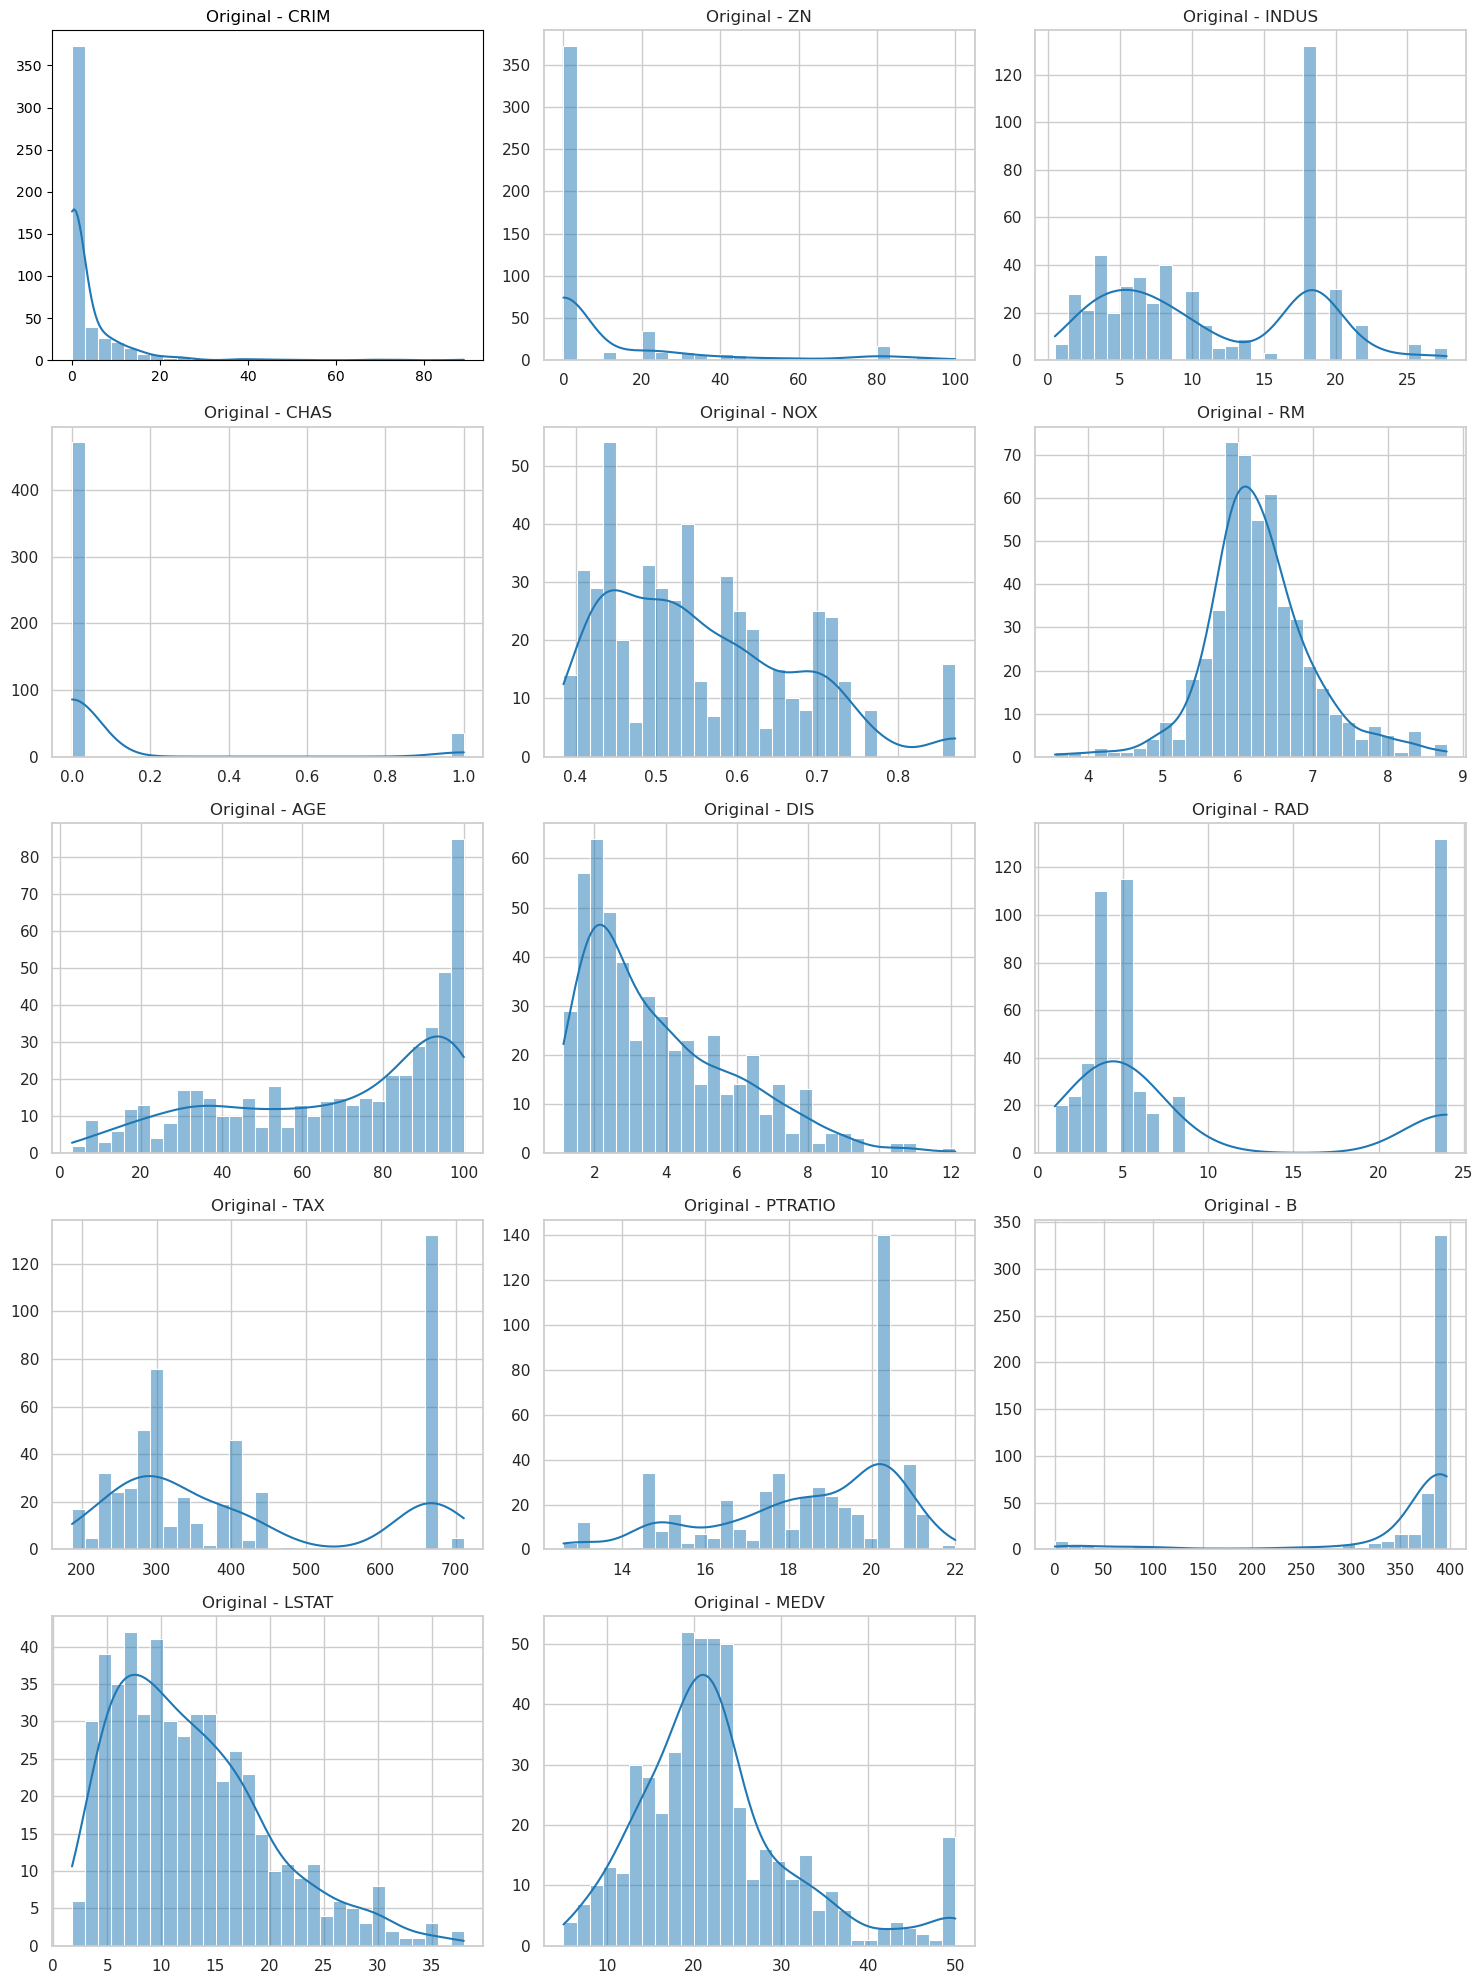

In [16]:
def plot_all_histograms(df, title_prefix=""):
    num_cols = df.select_dtypes(include=[np.number]).columns # numeric kolonlari alabiliriz.
    n_cols = 3 # tek col'da normalde 3 tane grafik kullanilir.
    n_rows = math.ceil(len(column_names) / n_cols) # .ceil metodu yukari yuvarmak icin kullanilabilir

    plt.figure(figsize=(5 * n_cols, 4 * n_rows))

    for i, col in enumerate(num_cols, 1):
        plt.subplot(n_rows, n_cols, i)
        sns.set_theme(style=("whitegrid"), palette="tab10")
        sns.histplot(df[col], bins=30, kde=True)
        plt.xlabel("")
        plt.ylabel("")
        plt.title(f"{title_prefix} {col}")
        
    plt.tight_layout()
    plt.show()

plot_all_histograms(df, title_prefix="Original -")        

In [17]:
df.apply(skew).sort_values(ascending=False) # verideki capikligi numeric olarak gosteriyor.
                                            # capiklik degeri yuksek kolonlarada transformantion yontemlerinin cok bir etkisi olmaz.

CRIM       5.207652
CHAS       3.395799
ZN         2.219063
MEDV       1.104811
DIS        1.008779
RAD        1.001833
LSTAT      0.903771
NOX        0.727144
TAX        0.667968
RM         0.402415
INDUS      0.294146
AGE       -0.597186
PTRATIO   -0.799945
B         -2.881798
dtype: float64

In [18]:
X = df.drop("MEDV", axis=1)
y = df["MEDV"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [29]:
col_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']

pt_x = PowerTransformer(method="yeo-johnson")

X_train_transformed = pt_x.fit_transform(X_train)
X_test_transformed = pt_x.transform(X_test)

In [30]:
X_train_transformed_df = pd.DataFrame(X_train_transformed, columns=col_names)
X_train_transformed_df

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,1.632418,-0.611431,1.025910,-0.278089,0.660141,-1.500965,1.088457,-0.820579,1.470669,1.398237,0.879939,-0.660366,1.519160
1,0.005892,-0.611431,-0.220198,-0.278089,0.016667,-0.660125,-0.535803,0.613586,-0.509927,-0.430816,1.429752,0.594880,-0.422094
2,-0.989911,1.645267,-0.589398,-0.278089,-1.118418,-0.364348,-1.560845,1.281746,-2.286892,-0.459128,-0.799009,-0.354822,-0.548273
3,1.441477,-0.611431,1.025910,-0.278089,0.660141,-0.258340,0.568585,-0.894412,1.470669,1.398237,0.879939,-2.788304,1.387242
4,0.106125,-0.611431,-0.220198,-0.278089,0.016667,-0.824422,-0.055165,0.305059,-0.509927,-0.430816,1.429752,0.447936,0.056144
...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,-0.673113,-0.611431,-0.152661,-0.278089,-0.160331,-0.657079,0.855059,-0.721840,-0.222363,0.176335,1.357553,0.596479,0.962458
400,-0.435557,1.582314,-0.421780,-0.278089,-0.784248,-0.626668,-1.020469,0.585628,-0.889170,-1.431685,-0.042918,0.377312,0.303307
401,-1.042367,1.698627,-1.605928,-0.278089,-1.157457,0.492714,-1.390408,1.643349,-0.509927,-0.702047,-0.760223,0.447626,-0.961807
402,1.570571,-0.611431,1.025910,-0.278089,1.443815,0.484543,0.971118,-0.798663,1.470669,1.398237,0.879939,-2.759879,1.385566


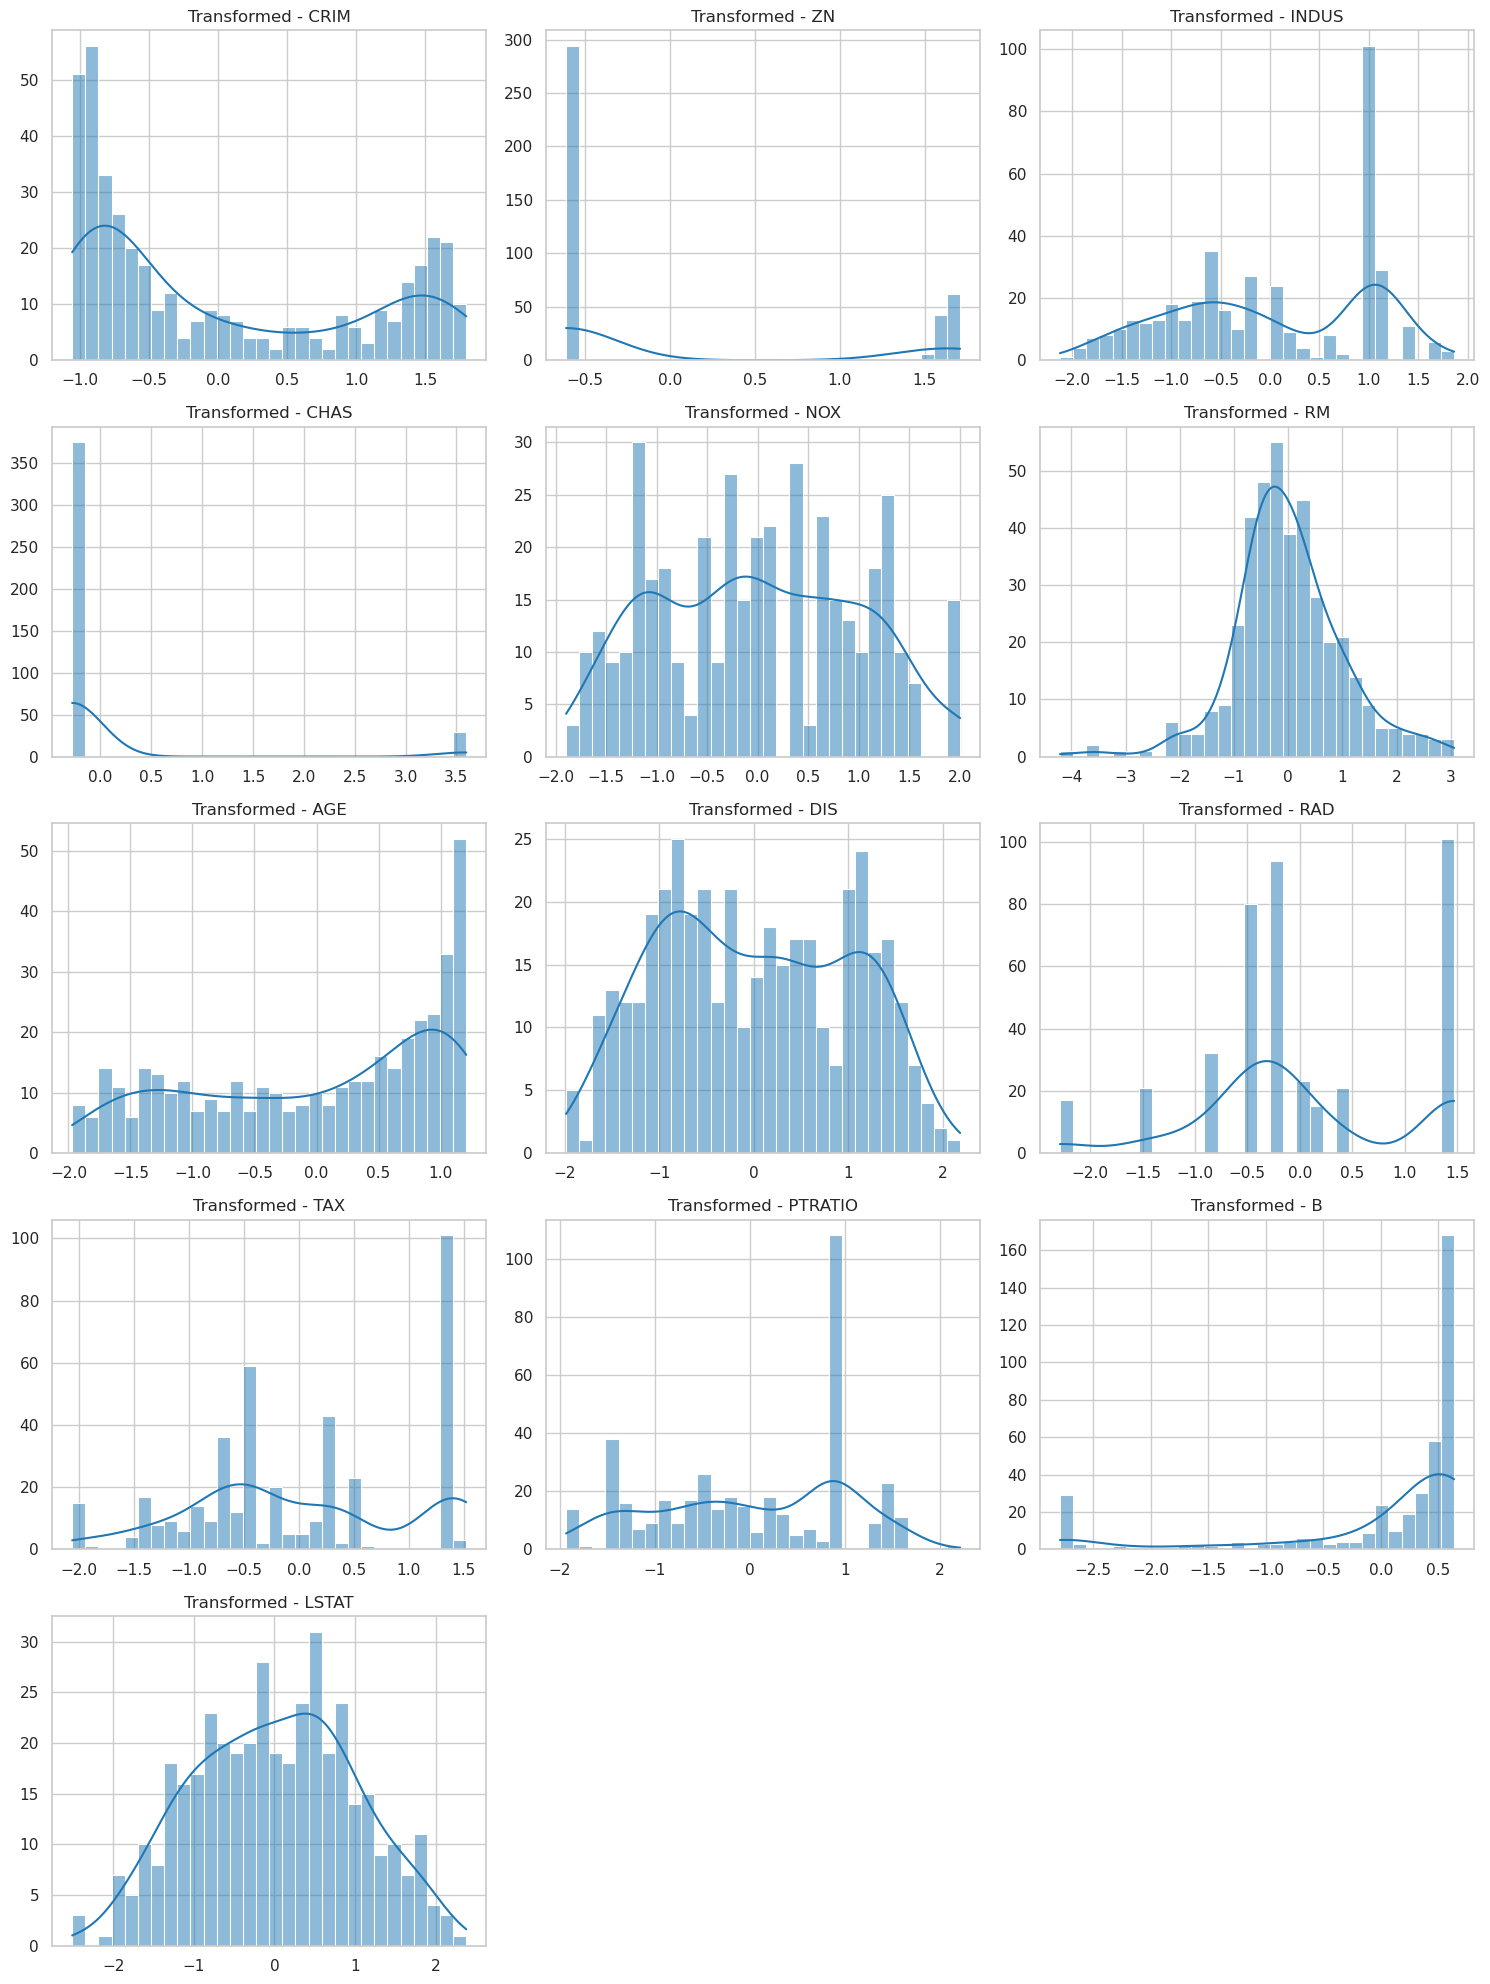

In [21]:
plot_all_histograms(X_train_transformed_df, title_prefix="Transformed -")        

In [22]:
y_train_transformed, lambda_y = boxcox(y_train)

In [23]:
def inverse_boxcox(y, lambda_):
    if lambda_ == 0:
        return np.exp(y) # e si alinir.

    else:
        return np.power(y * lambda_ + 1, 1 / lambda_)

In [24]:
model = LinearRegression()
model.fit(X_train_transformed, y_train_transformed)

y_pred_transformed = model.predict(X_test_transformed)

In [25]:
y_pred_original = inverse_boxcox(y_pred_transformed, lambda_y)

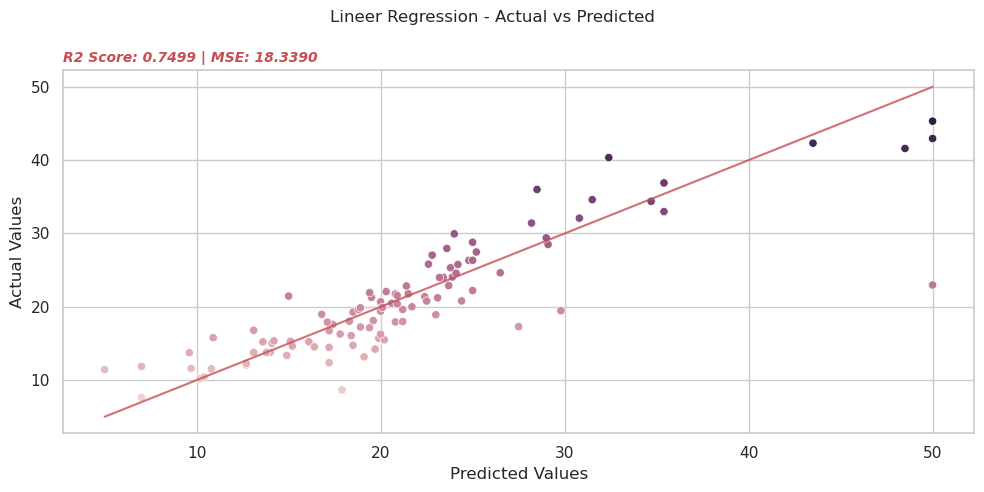

In [26]:
mse = mean_squared_error(y_test, y_pred_original)
r2 = r2_score(y_test, y_pred_original)


plt.figure(figsize=(10,5))
sns.set_theme(style=('whitegrid'))
sns.scatterplot(
    x = y_test,
    y = y_pred_original,
    legend = False,
    hue = y_pred_original
)
plt.suptitle("Lineer Regression - Actual vs Predicted",fontsize = 12)

plt.title(f"R2 Score: {r2:.4f} | MSE: {mse:.4f}", fontsize=10, loc='left', style='italic', fontweight="bold", color="r")
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.plot([y_test.min(),y_test.max()], [y_test.min(), y_test.max()], linewidth=1.5, alpha=0.8, color = 'r')

plt.tight_layout()
plt.show()

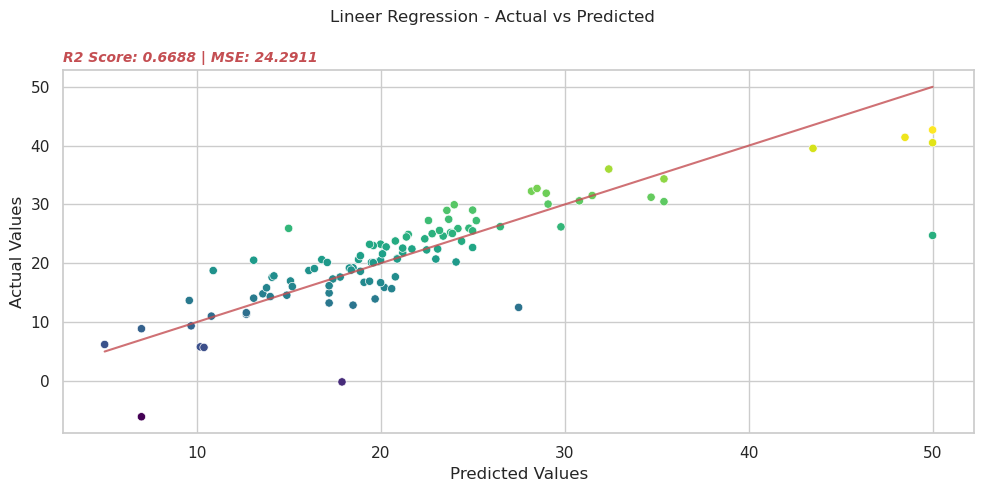

In [28]:
# transformation olmadan denersek 
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


plt.figure(figsize=(10,5))
sns.set_theme(style=('whitegrid'))
sns.scatterplot(
    x = y_test,
    y = y_pred,
    legend = False,
    hue = y_pred,
    palette="viridis"
)
plt.suptitle("Lineer Regression - Actual vs Predicted",fontsize = 12)

plt.title(f"R2 Score: {r2:.4f} | MSE: {mse:.4f}", fontsize=10, loc='left', style='italic', fontweight="bold", color="r")
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.plot([y_test.min(),y_test.max()], [y_test.min(), y_test.max()], linewidth=1.5, alpha=0.8, color = 'r')

plt.tight_layout()
plt.show()

### Sonuc olarak TRANSFORMATION yapildiginda LINEAR algoritmalar daha iyi sonuclar verecektir. ###